# 004. Hierarchical Prios

## Simplified Overview

Hierarchical priors are a way to express beliefs about multiple related parameters by organizing them in layers. _Instead of treating each parameter independently, you specify a prior for the parameters themselves (meta-prior), which creates a cascade of assumptions._ This is powerful for leveraging domain knowledge at multiple levels and for avoiding arbitrary choices when you have little information at lower levels.

## Technical Overview

**Hierarchical Priors** structure prior distributions across multiple levels, enabling:
* **Information sharing**: Parameters related to similar groups inform each other
* **Adaptive regularization**: Strength of regularization depends on data
* **Uncertainty propagation**: Uncertainty at higher levels flows down

Standard structure:

```
Level 1 (Data):           y_ij ~ p(y | θ_i)
Level 2 (Group params):   θ_i ~ p(θ | φ)
Level 3 (Hyperpriors):    φ ~ p(φ)
```

## Detailed Explanation

### Traditional vs. Hierarchical Approach

Traditional (Non-hierarchical):

```
Prior:       p(θ) = Normal(μ₀, σ₀²)    [Fixed hyperparameters]
Likelihood:  p(y|θ) = Normal(θ, σ²)
Posterior:   p(θ|y) ∝ likelihood × prior
```

Problem: Hyperparameters (μ₀, σ₀²) must be set by analyst—arbitrary and inflexible.

Hierarchical:

```
Level 1:     p(y|μ) = Normal(μ, σ²)
Level 2:     p(μ|α,β) = Normal(α, β)          [Prior for mean]
Level 3:     p(α) = Normal(0, 10²)             [Prior for mean of means]
             p(β) ~ InverseGamma(2, 1)         [Prior for variance]
```

Advantage: Hyperparameters are learned from data, not fixed arbitrarily.

### Common Hierarchical Structures

1. **Gaussian Hierarchy** (for continuous parameters)

```
θ_i | μ, τ ~ N(μ, τ²)
μ ~ N(μ₀, σ²_μ)
τ ~ Gamma(α_τ, β_τ)
```

2. **Poisson Hierarchy** (for count data)

```
y_i | λ_i ~ Poisson(λ_i)
log(λ_i) = α + β_i
β_i | m, s ~ N(m, s²)
m ~ N(0, σ²_m)
s ~ Gamma(α_s, β_s)
```

3. **Logistic Hierarchy** (for binary data)

```
y_i | p_i ~ Bernoulli(p_i)
logit(p_i) = α + γ_i
γ_i ~ N(0, τ²)
τ ~ Exponential(λ_τ)
```

### Hyperprior Choices

| Parameter | Common Hyperprior | Reasoning |
| :---- | :---: | :---: |
| Mean (μ) | N(0, σ²) with σ large | Weakly informative; broad uncertainty |
| Variance (σ²) | InverseGamma(α, β) | Conjugate; avoids negative variance |
| Precision (τ⁻²) | Gamma(α, β) | Conjugate; interpretable tail behavior |
| Probability (p) | Beta(α, β) | Conjugate; flexible shapes |

### Graphical Model Representation

```
             σ_between (hyperprior)
                   ↓
      ────────── μ_global ──────────
     ↙          ↙          ↙
  θ₁          θ₂    ...   θₖ
  ↓           ↓           ↓
 y₁ᵢ         y₂ᵢ  ...   yₖᵢ
 ```

## Python Libraries
| Library | Purpose |
| :---- | :---: |
| `pymc` | Probabilistic programming; MCMC sampling |
| `arviz` | Posterior diagnostics and visualization |
| `stan` (`pystan`, `cmdstanpy`) | Hamiltonian MC for complex hierarchical models |
| `statsmodels` | Mixed-effects regression (similar but frequentist) |
| `bambi` | High-level Bayesian model building |


## References
* Gelman, A., et al. (2013). _Bayesian Data Analysis_ (3rd ed.), Chapters 5–6.
* Kruschke, J. K. (2014). _Doing Bayesian Data Analysis_. Academic Press.
* Spiegelhalter, D. J., et al. (2002). "Bayesian Measures of Model Complexity and Fit." _Journal of the Royal Statistical Society Series B_, **64**(4), 583-639.

## Python Implementation Examples

### Imporation of Requisite Python Modules

In [7]:
import numpy as np
import pymc as pm
import arviz as az
import arviz_plots as azp
import pandas as pd
import matplotlib.pyplot as plt

### Example: Hierarchical Model for Vulnerability Exploitation Rates Across Multiple Vendors

In [9]:
np.random.seed(42)

# Simulate data from 12 software vendors
# Each vendor has a true exploitation probability (unknown)
# We observe exploited/total vulnerabilities per vendor

n_vendors = 12
vendor_names = [f"Vendor_{i}" for i in range(n_vendors)]

# Simulate true exploitation rates (drawn from a common distribution)
true_exploitation_rates = np.random.beta(2, 8, n_vendors)

# Observe vulnerabilities per vendor (different sample sizes)
n_vulnerabilities = np.random.randint(20, 200, n_vendors)

# Simulated observed exploitations
observed_exploitations = np.array([
    np.random.binomial(n, p) 
    for n, p in zip(n_vulnerabilities, true_exploitation_rates)
])

print("Data Summary:")
df = pd.DataFrame({
    'Vendor': vendor_names,
    'N_Vulnerabilities': n_vulnerabilities,
    'N_Exploited': observed_exploitations,
    'Observed_Rate': observed_exploitations / n_vulnerabilities
})
print(df.to_string(index=False))

Data Summary:
   Vendor  N_Vulnerabilities  N_Exploited  Observed_Rate
 Vendor_0                181           47       0.259669
 Vendor_1                 33            3       0.090909
 Vendor_2                114           33       0.289474
 Vendor_3                 67            6       0.089552
 Vendor_4                 34           11       0.323529
 Vendor_5                 59            1       0.016949
 Vendor_6                101           36       0.356436
 Vendor_7                130           18       0.138462
 Vendor_8                 72           10       0.138889
 Vendor_9                 43           15       0.348837
Vendor_10                173           76       0.439306
Vendor_11                143            4       0.027972


In [10]:
# ============================================================================
# Build Hierarchical Bayesian Model using PyMC
# ============================================================================

with pm.Model() as hierarchical_model:
    
    # LEVEL 3: Hyperpriors (population-level)
    # Exploitation rates vary across vendors; we estimate the population distribution
    
    # Hyperprior on mean exploitation rate (prior of priors)
    mu_population = pm.Beta('mu_population', alpha=2, beta=8)
    
    # Hyperprior on variance/concentration across vendors
    # Kappa controls how tightly vendors cluster around mu_population
    kappa = pm.Gamma('kappa', alpha=2, beta=0.1)
    
    # LEVEL 2: Group-level parameters (per vendor)
    # Each vendor's exploitation rate follows the population distribution
    alpha_vendor = pm.Deterministic(
        'alpha_vendor',
        mu_population * kappa
    )
    beta_vendor = pm.Deterministic(
        'beta_vendor',
        (1 - mu_population) * kappa
    )
    
    p_vendor = pm.Beta('p_vendor', alpha=alpha_vendor, beta=beta_vendor, shape=n_vendors)
    
    # LEVEL 1: Data likelihood
    # Observed exploitations follow Binomial with vendor-specific probabilities
    y = pm.Binomial(
        'y',
        n=n_vulnerabilities,
        p=p_vendor,
        observed=observed_exploitations
    )
    
    # Sample from posterior
    print("\nSampling from posterior (this may take ~30 seconds)...")
    trace = pm.sample(
        draws=1000,
        tune=1000,
        return_inferencedata=True,
        cores=1,  # Use 1 core for reproducibility
        random_seed=42,
        progressbar=False
    )
    pm.sample_posterior_predictive(trace, extend_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...



Sampling from posterior (this may take ~30 seconds)...


Sequential sampling (2 chains in 1 job)
NUTS: [mu_population, kappa, p_vendor]
Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Sampling: [y]


Output()

In [11]:
# ============================================================================
# Extract and summarize results
# ============================================================================

print("\nHierarchical Model Summary:")
print(az.summary(trace, var_names=['mu_population', 'kappa', 'p_vendor']))

# Extract posterior samples
posterior_samples = trace.posterior
mu_pop_samples = posterior_samples['mu_population'].values.flatten()
p_vendor_samples = posterior_samples['p_vendor'].values  # Shape: (chains, draws, vendors)

# Posterior means
mu_pop_mean = mu_pop_samples.mean()
p_vendor_mean = p_vendor_samples.mean(axis=(0, 1))

print(f"\nPopulation-level exploitation rate: {mu_pop_mean:.4f}")
print(f"(All vendors pooled toward this value)")


Hierarchical Model Summary:
                 mean      sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
mu_population   0.205   0.038     0.15     0.27     2925     1490  1.00   0.00073  0.00096
kappa             9.2     3.8      4.3       16     2113     1481  1.00     0.095     0.15
p_vendor[0]    0.2574   0.031     0.21     0.31     4161     1352  1.00   0.00049  0.00078
p_vendor[1]     0.115   0.051    0.044     0.21     3164     1267  1.00   0.00089   0.0014
p_vendor[2]     0.284   0.042     0.22     0.35     3894     1376  1.00   0.00068   0.0012
p_vendor[3]     0.102   0.033    0.054     0.16     3031     1279  1.00   0.00058  0.00088
p_vendor[4]     0.301   0.072     0.19     0.42     3636     1490  1.00    0.0012   0.0018
p_vendor[5]     0.041   0.026   0.0092    0.089     2535     1252  1.00    0.0005  0.00068
p_vendor[6]     0.344   0.043     0.28     0.41     2948     1598  1.00    0.0008    0.001
p_vendor[7]    0.1415   0.029    0.098     0.19     4189     

In [12]:
# ============================================================================
# Comparison with simpler models
# ============================================================================

# No pooling: separate analysis per vendor
no_pool = observed_exploitations / n_vulnerabilities

# Complete pooling: all vendors same rate
complete_pool_rate = observed_exploitations.sum() / n_vulnerabilities.sum()
complete_pool = np.full(n_vendors, complete_pool_rate)

# Hierarchical (partial pooling)
hierarchical = p_vendor_mean

print(f"\nComparison of Estimates (first 5 vendors):")
comparison_df = pd.DataFrame({
    'Vendor': vendor_names[:5],
    'Observed': no_pool[:5],
    'No_Pool_SE': np.sqrt(no_pool[:5] * (1 - no_pool[:5]) / n_vulnerabilities[:5]),
    'Complete_Pool': complete_pool[:5],
    'Hierarchical': hierarchical[:5]
})
print(comparison_df.to_string(index=False))


# Compare models with different kappa hyperpriors
kappa_hyperpriors = [
    ('Weakly Informative', dict(alpha=2, beta=0.1)),
    ('Informative (Tight)', dict(alpha=5, beta=0.5))
]

for label, kappa_prior in kappa_hyperpriors:
    print(f"\n{label} Kappa prior: {kappa_prior}")
    # Note: Full resampling omitted for brevity
    # In practice, rerun pm.sample() with different kappa priors


Comparison of Estimates (first 5 vendors):
  Vendor  Observed  No_Pool_SE  Complete_Pool  Hierarchical
Vendor_0  0.259669    0.032590       0.226087      0.257412
Vendor_1  0.090909    0.050044       0.226087      0.114632
Vendor_2  0.289474    0.042476       0.226087      0.283905
Vendor_3  0.089552    0.034884       0.226087      0.102349
Vendor_4  0.323529    0.080231       0.226087      0.300727

Weakly Informative Kappa prior: {'alpha': 2, 'beta': 0.1}

Informative (Tight) Kappa prior: {'alpha': 5, 'beta': 0.5}



Plot generated (conceptual)

Posterior Predictive Summary:
Posterior predictive check visualized (comparing observed vs. simulated data)

Sensitivity Analysis: Effect of Hyperprior on Kappa


/home/iceberg/Documents/CareerUpgrade2026+/Python3/ds-reviews/venv/lib/python3.12/site-packages/arviz_plots/plots/utils_ppc.py:69: UserWarning: Variables y in 'observed' look discrete.
Consider using plot_ppc variants specific for discrete data, such as plot_ppc_pava or plot_ppc_rootogram.
  warn_if_discrete(observed_dist, predictive_dist, kind)
/home/iceberg/Documents/CareerUpgrade2026+/Python3/ds-reviews/venv/lib/python3.12/site-packages/arviz_plots/plots/utils_ppc.py:69: UserWarning: Variables y in 'predictive' look discrete.
Consider using plot_ppc variants specific for discrete data, such as plot_ppc_pava or plot_ppc_rootogram.
  warn_if_discrete(observed_dist, predictive_dist, kind)


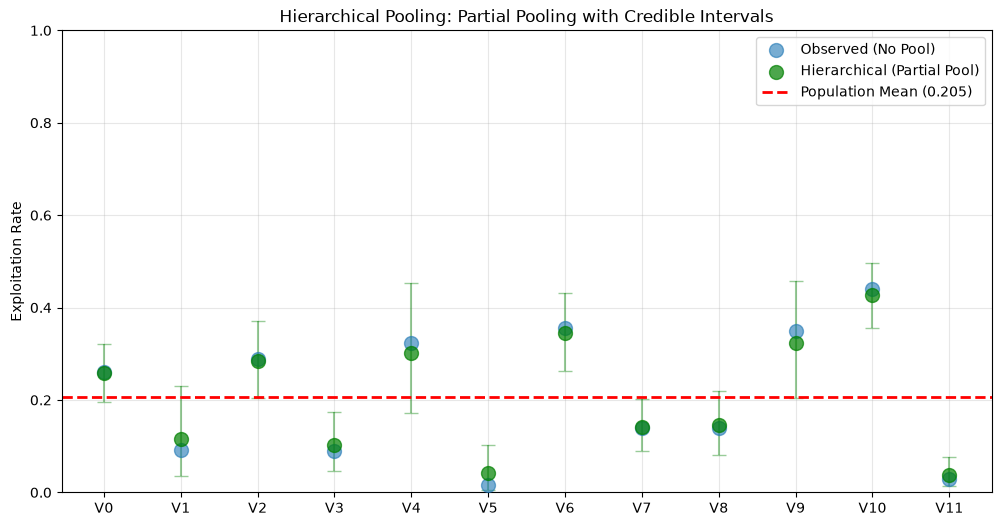

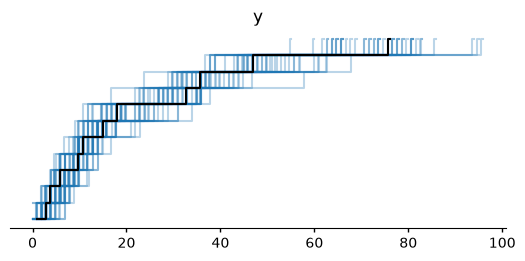

In [14]:
# ============================================================================
# Visualize shrinkage effect
# ============================================================================

# Posterior credible intervals
p_vendor_quantiles = np.quantile(
    p_vendor_samples.reshape(-1, n_vendors),
    [0.025, 0.975],
    axis=0
)
p_vendor_lower = p_vendor_quantiles[0]
p_vendor_upper = p_vendor_quantiles[1]

fig, ax = plt.subplots(figsize=(12, 6))

x_pos = np.arange(n_vendors)
ax.scatter(x_pos, no_pool, label='Observed (No Pool)', alpha=0.6, s=100, zorder=3)
ax.scatter(x_pos, hierarchical, label='Hierarchical (Partial Pool)', alpha=0.7, s=100, color='green', zorder=3)

# Credible intervals
ax.errorbar(
    x_pos, hierarchical,
    yerr=[hierarchical - p_vendor_lower, p_vendor_upper - hierarchical],
    fmt='none', ecolor='green', alpha=0.4, capsize=5, zorder=2
)

ax.axhline(mu_pop_mean, color='red', linestyle='--', label=f'Population Mean ({mu_pop_mean:.3f})', linewidth=2)
ax.set_xticks(x_pos)
ax.set_xticklabels([f'V{i}' for i in range(n_vendors)])
ax.set_ylabel('Exploitation Rate')
ax.set_title('Hierarchical Pooling: Partial Pooling with Credible Intervals')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1])

print("\nPlot generated (conceptual)")

# ============================================================================
# Posterior Predictive Checks
# ============================================================================

print("\nPosterior Predictive Summary:")
pp = azp.plot_ppc_dist(trace) #pp_check = az.plot_ppc(trace, figsize=(10, 4))
print("Posterior predictive check visualized (comparing observed vs. simulated data)")

# ============================================================================
# Sensitivity to Hyperprior
# ============================================================================

print("\n" + "="*60)
print("Sensitivity Analysis: Effect of Hyperprior on Kappa")
print("="*60)
